In [26]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time

#Mes imports

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Simulations')
import nano_objects
importlib.reload(nano_objects)
from nano_objects import *


os.chdir(r'C:\Users\nberr\Documents\Code\python\Modules')
import Slider_plot
importlib.reload(Slider_plot)
from Slider_plot import *
import Slider_plot_v2
importlib.reload(Slider_plot_v2)
from Slider_plot_v2 import *

from matplotlib.widgets import Slider, Button


## Create a Nano_objecterial class for future implementation

get gold index data

Get data

In [27]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Data_refractive_index'
fname = 'Au - jhonson Christy.csv'
data = get_permittivity_tabulated_data(dir_root, fname)

Lda = data['lambda']
Au_n = data['n']
Au_k = data['k']

interpolate data

In [28]:
n = sc.interpolate.interp1d(Lda, Au_n, kind='cubic', bounds_error=False, fill_value=1)
k = sc.interpolate.interp1d(Lda, Au_k, kind='cubic', bounds_error=False, fill_value=0)

Lambda = np.linspace(400, 1000, 1000)

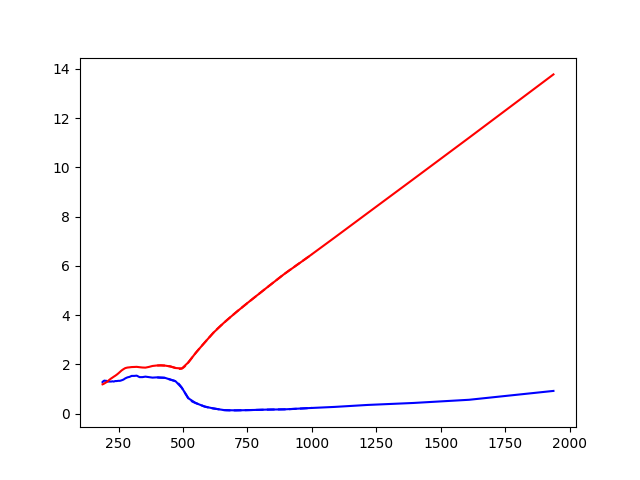

In [29]:
fig = plt.figure()

plt.plot(Lda, Au_n, color='b', label = 'n')
plt.plot(Lda, Au_k, color='r', label = 'k')

plt.plot(Lambda, n(Lambda), color='b', linestyle = '--')
plt.plot(Lambda, k(Lambda), color='r', linestyle = '--')

Create objects

In [30]:
a = 100e-9
c = 23e-9
eps_ext = 1.65**2 *np.ones(np.size(Lambda))


Gold_sphere = Sphere(r=a, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', eps_ext= eps_ext)
Gold_ellipse = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext)


print(Gold_ellipse.lda_SPR*1e9)


704504504504.5044


In [31]:
polar=(1,0,0)

Lambda = Gold_ellipse.wl

alpha_1 = Gold_sphere.polarizability
alpha_2 = Gold_ellipse.polarizability
sigma_abs1 = Gold_sphere.sigma_abs 
sigma_abs2 = Gold_ellipse.sigma_abs 

sigma_sca1 =  Gold_sphere.sigma_scat
sigma_sca2 =  Gold_ellipse.sigma_scat

sigma_ext1 = Gold_sphere.sigma_abs + Gold_sphere.sigma_scat
sigma_ext2 = Gold_ellipse.sigma_abs + Gold_ellipse.sigma_scat

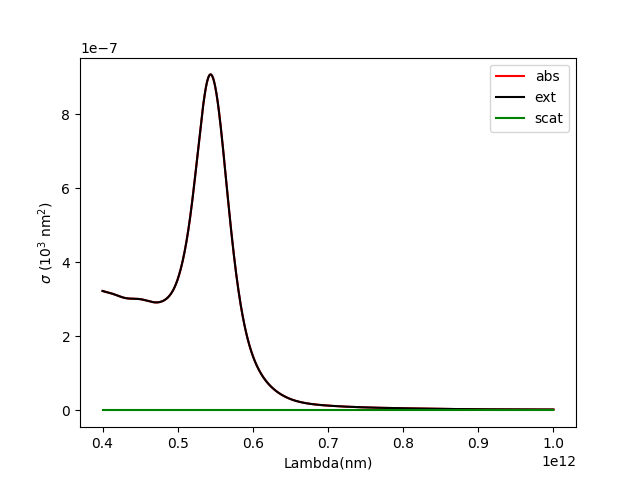

In [32]:
fig = plt.figure()

res_sphere = np.abs(Gold_sphere.polarizability)


plt.plot(Lambda*1e9, Gold_sphere.sigma_abs *1e15, color='red', label='abs')
plt.plot(Lambda*1e9, (Gold_sphere.sigma_abs + Gold_sphere.sigma_scat)*1e15, color='black', label='ext')
plt.plot(Lambda*1e9, Gold_sphere.sigma_scat*1e15, color='green', label='scat')



plt.xlabel('Lambda(nm)')

plt.ylabel(r'$\sigma$ ($10^3$ nm$^2$)')
plt.legend()

Polarizability definition

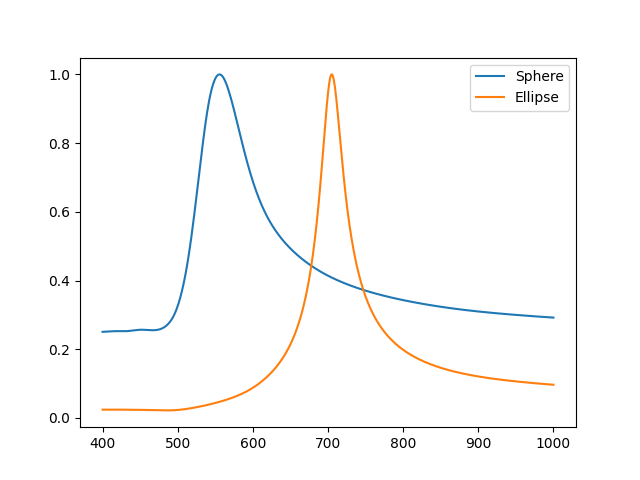

In [33]:
fig = plt.figure()

res_sphere = np.abs(Gold_sphere.polarizability)
res_ellipse = np.abs(Gold_ellipse.polarizability)

plt.plot(Gold_sphere.wl, res_sphere / np.max(res_sphere), label='Sphere' )
plt.plot(Gold_ellipse.wl, res_ellipse/np.max(res_ellipse), label='Ellipse')
plt.legend()


<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
C:\Users\nberr\AppData\Local\Temp\ipykernel_19260\2463317300.py:5: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel('$\sigma_{ext}$ (10$^2$ nm$^2$)')


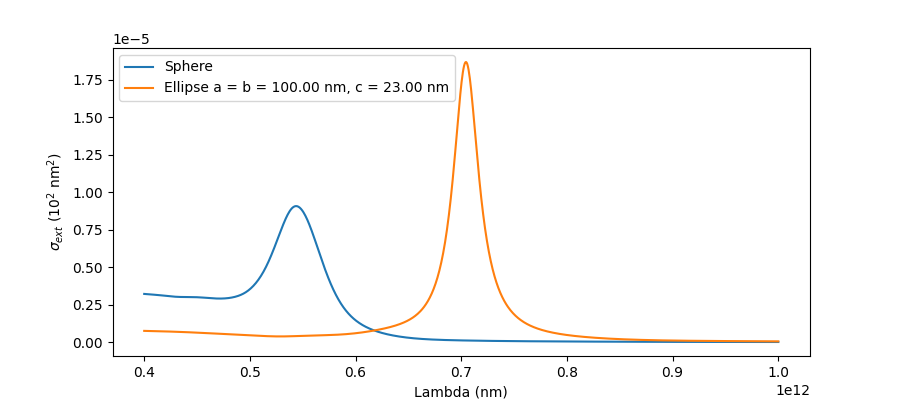

In [34]:
fig = plt.figure(figsize=(9,4))
plt.plot(Lambda*1e9, sigma_ext1*1e16, label='Sphere')
plt.plot(Lambda*1e9, sigma_ext2*1e16, label='Ellipse a = b = {:.2f} nm, c = {:.2f} nm'.format(a*1e9, c*1e9))
plt.xlabel('Lambda (nm)')
plt.ylabel('$\sigma_{ext}$ (10$^2$ nm$^2$)')
plt.legend()


Text(0.5, 1.0, 'Ellipsoid')

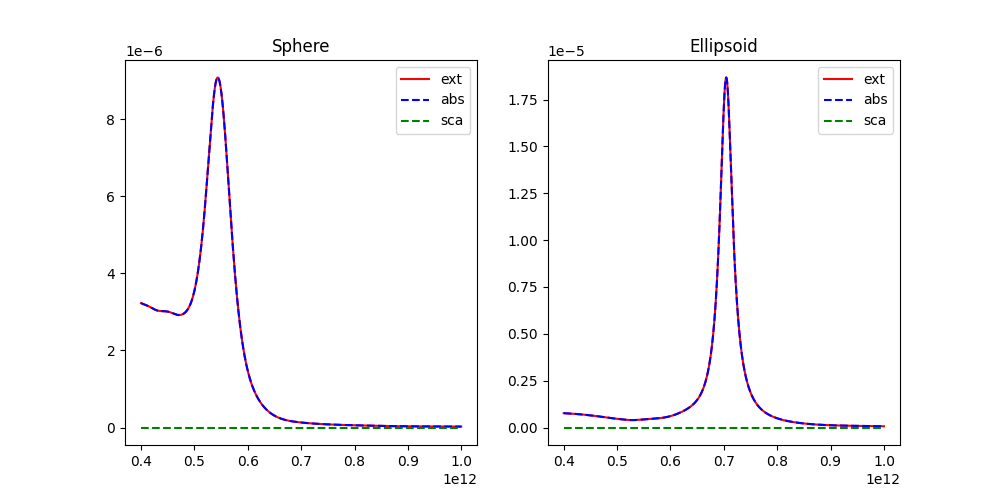

In [35]:
fig ,ax = plt.subplots(ncols=2, figsize=(10, 5))

ax[0].plot(Lambda*1e9, sigma_ext1*1e16, color='r', label='ext')
ax[0].plot(Lambda*1e9, sigma_abs1*1e16, color='b', linestyle='--', label='abs')
ax[0].plot(Lambda*1e9, sigma_sca1*1e16, color='g', linestyle='--', label='sca')
ax[0].legend()
ax[0].set_title('Sphere')

ax[1].plot(Lambda*1e9, sigma_ext2*1e16, color='r', label='ext')
ax[1].plot(Lambda*1e9, sigma_abs2*1e16, color='b', linestyle='--', label='abs')
ax[1].plot(Lambda*1e9, sigma_sca2*1e16, color='g', linestyle='--', label='sca')
ax[1].legend()
ax[1].set_title('Ellipsoid')


Text(0.5, 1.0, 'Sphere')

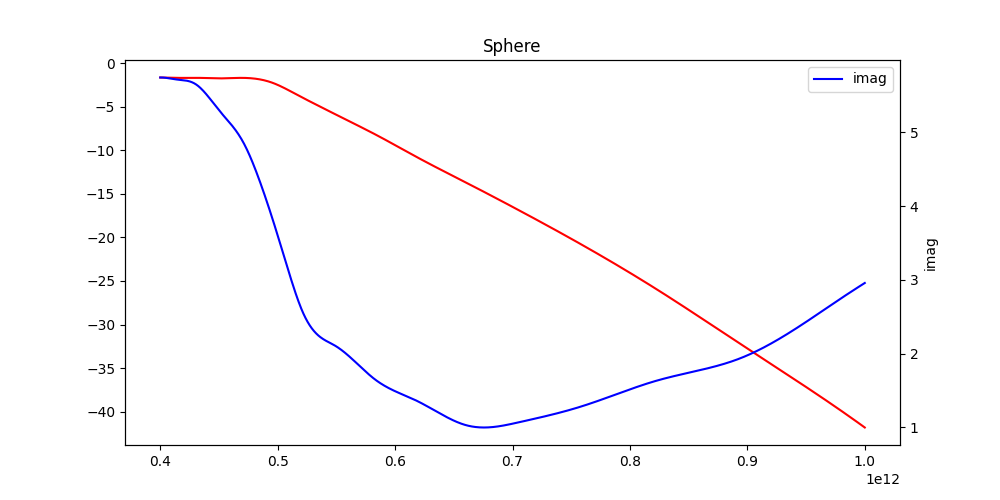

In [36]:
fig = plt.figure(figsize=(10, 5))

plt.plot(Lambda*1e9, Gold_sphere.eps_1, color='r', label='real')
axx = plt.twinx()
axx.plot(Lambda*1e9, Gold_sphere.eps_2, color='b', label='imag')

plt.ylabel('imag')
plt.legend()
axx.legend()
plt.title('Sphere')

Text(0.5, 1.0, 'Sphere')

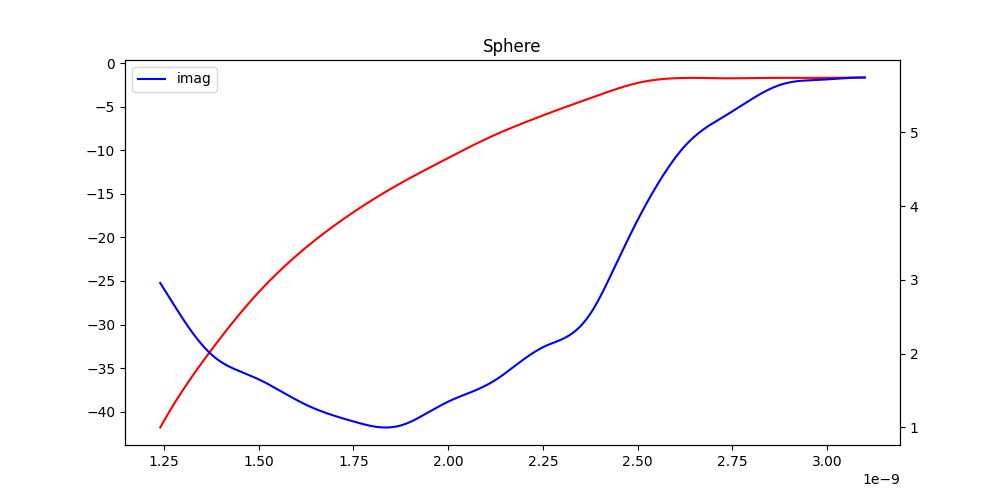

In [37]:

h = sc.constants.h 
c = sc.constants.c 
eV = sc.constants.e 
Energy = h*c/Lambda

fig = plt.figure(figsize=(10, 5))

plt.plot(Energy/eV, Gold_sphere.eps_1, color='r', label='real')
axx = plt.twinx()
axx.plot(Energy/eV, Gold_sphere.eps_2, color='b', label='imag')

plt.legend()
axx.legend()
plt.title('Sphere')

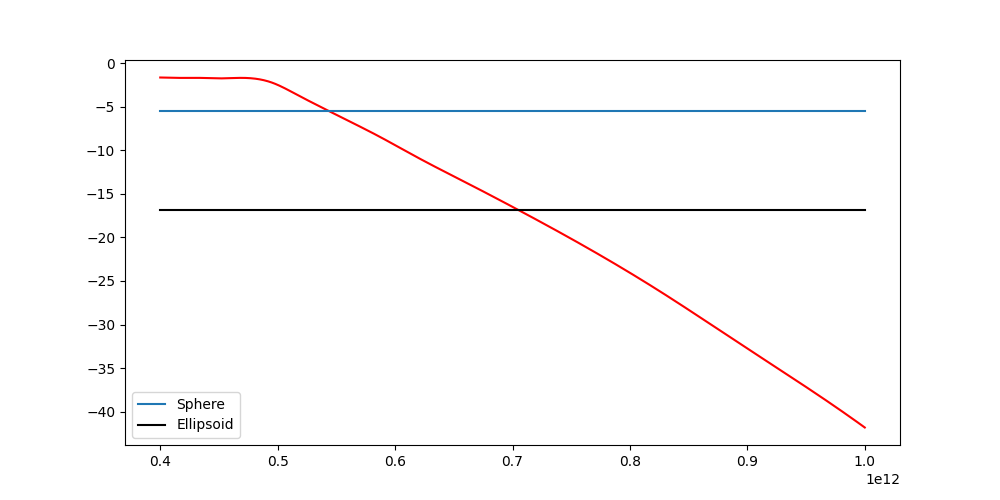

In [38]:
fig = plt.figure(figsize=(10, 5))

plt.plot(Lambda*1e9, Gold_sphere.eps_1, color='r')


L1 = Gold_sphere.L
H1 = (1-L1)/L1

L2 = Gold_ellipse.L
H2 = (1-L2)/L2

plt.plot(Lambda*1e9, -H1*eps_ext, label='Sphere')
plt.plot(Lambda*1e9, -H2*eps_ext, label='Ellipsoid', color='black')

plt.legend()

## Try to make some parameter vary

In [39]:
slider_bool = 1

In [40]:
def plot_LSPR_shift(arg_cte, arg_var, labels=False) :
    delta_eps1 = arg_var[0]
    delta_eps2 = arg_var[1]
    delta_eps_ext = arg_var[2]


    mat = arg_cte[0]

    #vary matter
    mat.eps_1 += delta_eps1
    mat.eps_2 += delta_eps2
    mat.eps_ext += delta_eps_ext
    mat.update()

    sigma_abs, sigma_scat, sigma_ext = mat.sigma_abs, mat.sigma_scat, mat.sigma_ext

    #reset matter
    mat.eps_1 -= delta_eps1
    mat.eps_2 -= delta_eps2
    mat.eps_ext -= delta_eps_ext
    mat.update()

    Labels = []
    if labels :
        Labels.append(Label_info(label = 'Sigma_abs', linestyle = 'dashed', color = 'blue'))
        Labels.append(Label_info(label = 'Sigma_scat', linestyle = 'dashed', color = 'red'))
        Labels.append(Label_info(label = 'Sigma_ext', linestyle = '-', color = 'black'))

    return(mat.wl*1e9, [sigma_abs*1e16, sigma_scat*1e16, sigma_ext*1e16], Labels)


def plot_LSPR_delta(arg_cte, arg_var, labels=False) :

    delta_eps1 = arg_var[0]
    delta_eps2 = arg_var[1]
    delta_eps_ext = arg_var[2]


    mat = arg_cte[0]


    sigma_abs_i, sigma_scat_i, sigma_ext_i = mat.sigma_abs, mat.sigma_scat, mat.sigma_ext

    #vary matter
    mat.eps_1 += delta_eps1
    mat.eps_2 += delta_eps2
    mat.eps_ext += delta_eps_ext
    mat.update()

    sigma_abs_f, sigma_scat_f, sigma_ext_f = mat.sigma_abs, mat.sigma_scat, mat.sigma_ext
    
    # delta_abs = sigma_abs_f - sigma_abs_i
    # delta_scat =  sigma_scat_f - sigma_scat_i
    # delta_ext =  sigma_ext_f - sigma_ext_i

    delta_abs = np.abs(sigma_abs_f - sigma_abs_i)
    delta_scat =  np.abs(sigma_scat_f - sigma_scat_i)
    delta_ext =  np.abs(sigma_ext_f - sigma_ext_i)

    #reset matter
    mat.eps_1 -= delta_eps1
    mat.eps_2 -= delta_eps2
    mat.eps_ext -= delta_eps_ext
    mat.update()

    Labels = []
    if labels :
        Labels.append(Label_info(label = 'Delta_abs', linestyle = 'dashed', color = 'blue'))
        Labels.append(Label_info(label = 'Delta_scat', linestyle = 'dashed', color = 'red'))
        Labels.append(Label_info(label = 'Delta_ext', linestyle = '-', color = 'black'))

    return(mat.wl*1e9, [delta_abs*1e16, delta_scat*1e16, delta_ext*1e16], Labels)


Figure(900x400)
Axes(0.125,0.11;0.775x0.77)
['$\\Delta$ eps_1', '$\\Delta$ eps_2', '$\\Delta$ eps_ext']


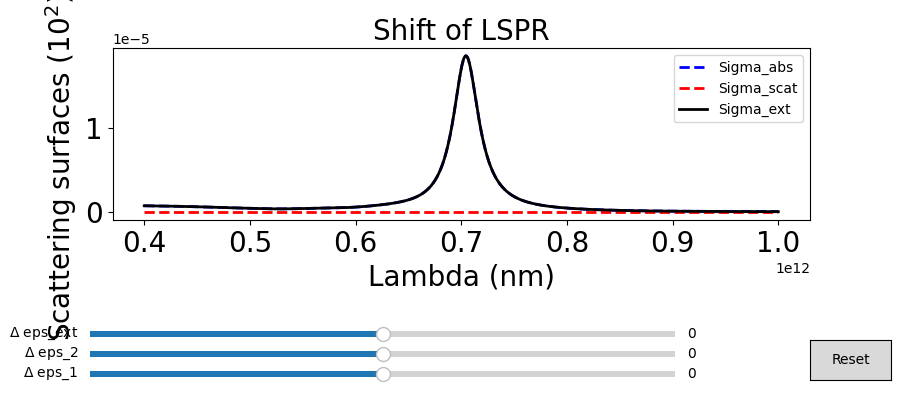

In [41]:
LSPR_shift_plot = Param_slider()
LSPR_shift_plot.add_param(r'$\Delta$ eps_1', 0, -1, 1)
LSPR_shift_plot.add_param(r'$\Delta$ eps_2', 0, -1, 1)
LSPR_shift_plot.add_param(r'$\Delta$ eps_ext', 0, -1, 1)

LSPR_shift_plot.plot(plot_LSPR_shift, [Gold_ellipse], titre='Shift of LSPR', xtitle='Lambda (nm)', ytitle=r'Scattering surfaces (10$^2$) nm$^2$')

Figure(640x480)
Axes(0.125,0.11;0.775x0.77)
['$\\Delta$ eps_1', '$\\Delta$ eps_2', '$\\Delta$ eps_ext']


C:\Users\nberr\AppData\Local\Temp\ipykernel_19260\2899347848.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax  = plt.subplots()


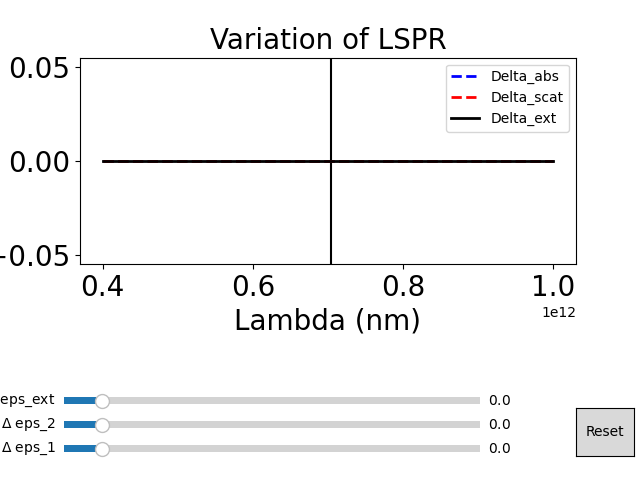

In [42]:
LSPR_delta_plot = Param_slider()
LSPR_delta_plot.add_param(r'$\Delta$ eps_1', 0, -0.1, 1)
LSPR_delta_plot.add_param(r'$\Delta$ eps_2', 0, -0.1, 1)
LSPR_delta_plot.add_param(r'$\Delta$ eps_ext', 0, -0.1, 1)

fig, ax  = plt.subplots()
plt.axvline(Gold_ellipse.wl[np.argmax(Gold_ellipse.sigma_ext)]*1e9, color='black')

LSPR_delta_plot.plot(plot_LSPR_delta, [Gold_ellipse], titre='Variation of LSPR', xtitle='Lambda (nm)', ytitle=r'$\Delta \sigma_{ext}$ (10$^2$) nm$^2$', otherplot_exist=True, otherplot=(fig, ax))

In [43]:
def oscillations(T, mat = Gold_sphere, tau = 1e-12, f = 10e-9, delta_eps_1 = 0, delta_eps_2=0, delta_eps_ext=0, lda=450e-9) :

    
    wl_ini = mat.wl
    eps_1_ini = mat.eps_1
    eps_2_ini = mat.eps_2
    eps_ext_ini = mat.eps_ext

    lda_index = np.searchsorted(wl_ini, lda)

    osc_amort = np.exp(-T/tau) * np.sin(2*np.pi*f*T)
    sigma_ext_offset = mat.sigma_ext[lda_index]

    mat.wl = wl_ini[lda_index]
    mat.eps_1 = eps_1_ini[lda_index] + delta_eps_1*osc_amort
    mat.eps_2 = eps_2_ini[lda_index] + delta_eps_2*osc_amort
    mat.eps_ext = eps_ext_ini[lda_index] + delta_eps_ext*osc_amort
    mat.update()
    
    delta_sigma_ext = mat.sigma_ext - sigma_ext_offset

    mat.wl = wl_ini
    mat.eps_1 = eps_1_ini
    mat.eps_2 = eps_2_ini
    mat.eps_ext = eps_ext_ini
    mat.update()
    
    return(delta_sigma_ext)

def LSPR_delta( mat = Gold_sphere, tau = 1e-12, delta_eps_1 = 0, delta_eps_2=0, delta_eps_ext=0, lda=450e-9, f=0) :

    sigma_ext_i = mat.sigma_ext

    #vary matter
    mat.eps_1 += delta_eps_1
    mat.eps_2 += delta_eps_2
    mat.eps_ext += delta_eps_ext
    mat.update()

    sigma_ext_f = mat.sigma_ext
    
    delta_ext =  sigma_ext_f - sigma_ext_i

    #reset matter
    mat.eps_1 -= delta_eps_1
    mat.eps_2 -= delta_eps_2
    mat.eps_ext -= delta_eps_ext
    mat.update()

    return(np.abs(delta_ext))

    

    

In [44]:
mat = Gold_ellipse

oscillation_arguments_init = {
    'tau': 100e-12, 
    'f': 10e9, 
    'delta_eps_1': 0, 
    'delta_eps_2': 0, 
    'delta_eps_ext': 0,
    'lda': mat.wl_res,  
    'mat': mat,
}

oscillation_arguments = oscillation_arguments_init.copy()
T = np.linspace(0, 1000e-12, 1000)


In [45]:
Time_oscillation_sliders = Param_slider2()
Time_oscillation_sliders.add_param('delta_eps_1', oscillation_arguments_init['delta_eps_1'], -0.1, 0.1)
Time_oscillation_sliders.add_param('delta_eps_2', oscillation_arguments_init['delta_eps_2'], -0.1, 0.1)
Time_oscillation_sliders.add_param('delta_eps_ext', oscillation_arguments_init['delta_eps_ext'], -0.1, 0.1)
Time_oscillation_sliders.add_param('tau', oscillation_arguments_init['tau'], 1e-12, 200e-12, value_label='ps', label_power=1e12)
Time_oscillation_sliders.add_param('f', oscillation_arguments_init['f'] , 1e9, 100e9, value_label='GHz', label_power=1e-9)
Time_oscillation_sliders.add_param('lda', oscillation_arguments_init['lda'] , mat.wl.min(), mat.wl.max(), value_label='nm', label_power=1e9)

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:37: SyntaxWarning: invalid escape sequence '\D'
<>:52: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:37: SyntaxWarning: invalid escape sequence '\D'
<>:52: SyntaxWarning: invalid escape sequence '\D'
C:\Users\nberr\AppData\Local\Temp\ipykernel_19260\2765283818.py:9: SyntaxWarning: invalid escape sequence '\D'
  ax1.set_ylabel('$\Delta \sigma_{ext} (\lambda)$ (10$^{2}$ nm$^2$)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_19260\2765283818.py:15: SyntaxWarning: invalid escape sequence '\D'
  ax2.set_ylabel('$\Delta \sigma_{ext}$(t) (10$^{2}$ nm$^2$)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_19260\2765283818.py:37: SyntaxWarning: invalid escape sequence '\D'
  ax1.set_ylabel('$\Delta \sigma_{ext} (\lambda)$ (10$^{2}$ nm$^2$)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_19260\276528

IndexError: invalid index to scalar variable.

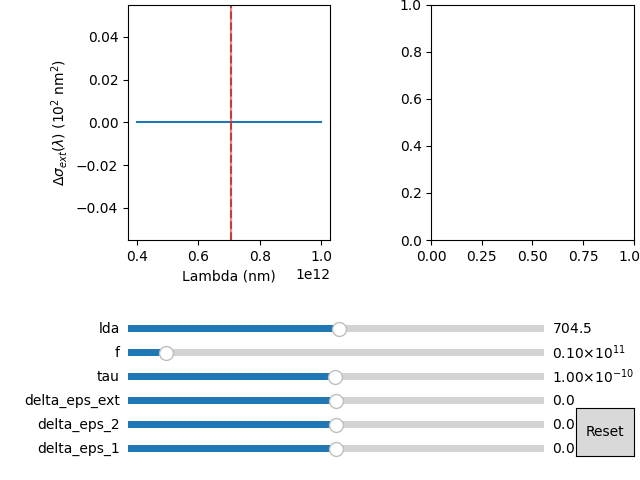

In [46]:
fig, (ax1, ax2) = plt.subplots(ncols=2)
fig.subplots_adjust(left=0.2, bottom=0.5, right=0.99, top=0.99, wspace=0.5, hspace=0.05)

Time_oscillation_sliders.create_Sliders(fig)
bouton = Button(ax=fig.add_axes([0.9, 0.05, 0.09, 0.1]), label ='Reset')

ax1.plot(mat.wl*1e9, LSPR_delta(**oscillation_arguments_init)*1e16)
ax1.set_xlabel('Lambda (nm)')
ax1.set_ylabel('$\Delta \sigma_{ext} (\lambda)$ (10$^{2}$ nm$^2$)')
ax1.axvline(oscillation_arguments_init['lda']*1e9, color='grey', linestyle='dashed')
ax1.axvline(mat.wl_res*1e9, color='red', alpha=0.5)

Y2 = ax2.plot(T, oscillations(T, **oscillation_arguments_init))
ax2.set_xlabel('Time (ps)')
ax2.set_ylabel('$\Delta \sigma_{ext}$(t) (10$^{2}$ nm$^2$)')
# Updating plots

def update_sliders(val):

    #Updating parameters and sliders print
    for key in Time_oscillation_sliders.val_init :
        slid = Time_oscillation_sliders.Sliders[key]
        label_power = Time_oscillation_sliders.label_power[key]
        value_label = Time_oscillation_sliders.value_label[key]
        oscillation_arguments[key] = slid.val

        slid.valtext.set_text('{:.3f} '.format(slid.val*label_power) + value_label)

    #updating plots
    delta_sigma_ext= LSPR_delta(**oscillation_arguments)
    osc = oscillations(T, **oscillation_arguments)

    
    plt.sca(ax1) #set ax2 as the active axis
    plt.cla() #clear the active axis
    ax1.set_xlabel('Lambda (nm)')
    ax1.set_ylabel('$\Delta \sigma_{ext} (\lambda)$ (10$^{2}$ nm$^2$)')
    
    ax1.axvline(oscillation_arguments['lda']*1e9, color='grey', linestyle='dashed')
    ax1.axvline(mat.wl_res*1e9, color='red', alpha=0.5)
    ax1.plot(mat.wl*1e9, delta_sigma_ext*1e16)

    ax1.relim()
    ax1.autoscale_view()




    plt.sca(ax2) #set ax2 as the active axis
    plt.cla() #clear the active axis
    ax2.set_xlabel('Time (ps)')
    ax2.set_ylabel('$\Delta \sigma_{ext}$(t) (10$^{2}$ nm$^2$)')
    
    ax2.plot(T*1e12, osc*1e16)

    ax2.set_ylim(-np.abs(delta_sigma_ext).max()*1e16-osc[-1]+1e-16, np.abs(delta_sigma_ext).max()*1e16-osc[-1]-1e-16)
    ax2.relim()
    ax2.autoscale_view()

    fig.canvas.draw_idle()

def update_button(val) :
    #Reseting parameters and sliders print
    for key in Time_oscillation_sliders.val_init :
        slid = Time_oscillation_sliders.Sliders[key]
        slid.reset
        
        
        slid.set_val(slid.valinit)

        update_sliders(0)



for key in Time_oscillation_sliders.Sliders :
    slid = Time_oscillation_sliders.Sliders[key]
    slid.on_changed(update_sliders)
bouton.on_clicked(update_button)